In [ ]:
import re, unicodedata, difflib, getpass
from urllib import robotparser
import requests, numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from bs4 import BeautifulSoup
from scipy import stats
sns.set_theme(style="whitegrid")

API_KEY = getpass.getpass("Вставь API ключ: ")
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_Premier_League_stadiums"
HEADERS = {"User-Agent": "SIS-student-project/1.0 (educational use)"}

In [38]:
url = "https://api.football-data.org/v4/competitions/PL/standings"
auth = {"X-Auth-Token": API_KEY}
r = requests.get(url, headers=auth, params={"season": 2025}, timeout=30)
if r.status_code == 403:
    r = requests.get(url, headers=auth, timeout=30)
r.raise_for_status()
payload = r.json()
print(payload["season"]["startDate"], payload["season"]["endDate"], payload["season"].get("currentMatchday"))

total = next(s for s in payload["standings"] if s["type"] == "TOTAL")
df_api = pd.json_normalize(total["table"])
df_api.head()

2025-08-15 2026-05-24 38


,position,playedGames,form,won,draw,lost,points,goalsFor,goalsAgainst,goalDifference,team.id,team.name,team.shortName,team.tla,team.crest
0,1,38,"W,W,W,W,W",26,7,5,85,71,27,44,57,Arsenal FC,Arsenal,ARS,https://crests.football-data.org/57.png
1,2,38,"L,D,W,W,D",23,9,6,78,77,35,42,65,Manchester City FC,Man City,MCI,https://crests.football-data.org/65.png
2,3,38,"W,W,D,W,W",20,11,7,71,69,50,19,66,Manchester United FC,Man United,MUN,https://crests.football-data.org/66.png
3,4,38,"W,W,D,L,L",19,8,11,65,56,49,7,58,Aston Villa FC,Aston Villa,AVL,https://crests.football-data.org/58.png
4,5,38,"D,L,D,L,W",17,9,12,60,63,53,10,64,Liverpool FC,Liverpool,LIV,https://crests.football-data.org/64.png


In [30]:
rp = robotparser.RobotFileParser()
rp.parse(requests.get("https://en.wikipedia.org/robots.txt", headers=HEADERS, timeout=30).text.splitlines())
print("Разрешено:", rp.can_fetch(HEADERS["User-Agent"], WIKI_URL))

html = requests.get(WIKI_URL, headers=HEADERS, timeout=30).text
soup = BeautifulSoup(html, "html.parser")

table = None
for t in soup.select("table.wikitable"):
    for sup in t.find_all("sup"):
        sup.decompose()
    heads = [c.get_text(" ", strip=True).lower() for c in t.find("tr").find_all(["th", "td"])]
    if any("stadium" in h for h in heads) and any(("club" in h or "team" in h) for h in heads) and any("capacity" in h for h in heads):
        table = t
        break
print(heads)

i_st = next(i for i, h in enumerate(heads) if "stadium" in h)
i_cl = next(i for i, h in enumerate(heads) if "club" in h or "team" in h)
i_cp = next(i for i, h in enumerate(heads) if "capacity" in h)
i_cs = next(i for i, h in enumerate(heads) if "closed" in h)

rows = []
for tr in table.find_all("tr")[1:]:
    cells = tr.find_all(["th", "td"])
    if len(cells) != len(heads):
        continue
    rows.append({"club_wiki": cells[i_cl].get_text(" ", strip=True),
                 "stadium": cells[i_st].get_text(" ", strip=True),
                 "capacity_raw": cells[i_cp].get_text(" ", strip=True),
                 "closed": cells[i_cs].get_text(" ", strip=True)})
df_wiki = pd.DataFrame(rows)
print("Всего строк:", len(df_wiki))

df_wiki = df_wiki[~df_wiki["closed"].str.contains(r"\d")].reset_index(drop=True)
print("Действующих стадионов:", len(df_wiki))
df_wiki.head()

Разрешено: True
['stadium', 'image', 'club', 'location', 'opened', 'closed', 'capacity', 'pitch length (m)', 'pitch width (m)', 'coordinates', 'ref.']
Всего строк: 63
Действующих стадионов: 52


,club_wiki,stadium,capacity_raw,closed
0,Liverpool,Anfield,"61,276",
1,Stoke City,bet365 Stadium Formerly Britannia Stadium,"30,089",
2,Blackpool,Bloomfield Road,"16,220",
3,Oldham Athletic,Boundary Park,"13,559",
4,Sheffield United,Bramall Lane,"32,050",


In [31]:
df_api = df_api.rename(columns={
    "team.name": "club_api", "team.tla": "tla", "playedGames": "played",
    "won": "wins", "draw": "draws", "lost": "losses",
    "goalsFor": "goals_for", "goalsAgainst": "goals_against", "goalDifference": "goal_diff"
})[["position", "club_api", "tla", "played", "wins", "draws", "losses",
    "goals_for", "goals_against", "goal_diff", "points"]]
print("Пропуски API:", df_api.isna().sum().sum(), "| дубликаты:", df_api["club_api"].duplicated().sum())

def parse_capacity(text):
    text = re.sub(r"\[.*?\]", "", str(text))
    m = re.search(r"\d[\d,\.\s]*", text)
    return int(re.sub(r"\D", "", m.group())) if m else np.nan

df_wiki["capacity"] = df_wiki["capacity_raw"].map(parse_capacity)
df_wiki["club_wiki"] = df_wiki["club_wiki"].str.replace(r"\[.*?\]", "", regex=True).str.strip()
df_wiki = df_wiki.dropna(subset=["capacity"]).reset_index(drop=True)
df_wiki["capacity"] = df_wiki["capacity"].astype(int)
print("Пропуски вместимости убраны, строк:", len(df_wiki))
df_wiki.head()

Пропуски API: 0 | дубликаты: 0
Пропуски вместимости убраны, строк: 52


,club_wiki,stadium,capacity_raw,closed,capacity
0,Liverpool,Anfield,"61,276",,61276
1,Stoke City,bet365 Stadium Formerly Britannia Stadium,"30,089",,30089
2,Blackpool,Bloomfield Road,"16,220",,16220
3,Oldham Athletic,Boundary Park,"13,559",,13559
4,Sheffield United,Bramall Lane,"32,050",,32050


In [32]:
STOP = {"fc", "afc", "cf", "the"}
def make_key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode().lower()
    s = s.replace("&", " and ")
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return " ".join(t for t in s.split() if t not in STOP)

df_api["key"] = df_api["club_api"].map(make_key)
df_wiki["key"] = df_wiki["club_wiki"].map(make_key)
df_wiki["key"] = df_wiki["key"].replace({"crystal palace wimbledon": "crystal palace"})

dups = df_wiki[df_wiki["key"].duplicated(keep=False)]
if len(dups):
    print("Клубы с несколькими стадионами (оставляем первый):")
    print(dups[["club_wiki", "stadium", "capacity"]])
df_wiki = df_wiki.drop_duplicates("key").reset_index(drop=True)

wk = list(df_wiki["key"])
def fix(k):
    if k in wk: return k
    c = difflib.get_close_matches(k, wk, n=1, cutoff=0.8)
    if c: print("нечёткое совпадение:", k, "->", c[0])
    return c[0] if c else k
df_api["key"] = df_api["key"].map(fix)

df = df_api.merge(df_wiki[["key", "stadium", "capacity"]], on="key", how="left", validate="one_to_one")
print("В API:", len(df_api), "| после слияния:", len(df), "| без вместимости:", df["capacity"].isna().sum())
print(df[df["capacity"].isna()][["club_api"]])

Клубы с несколькими стадионами (оставляем первый):
   club_wiki                 stadium  capacity
20   Everton           Goodison Park     39414
22   Everton  Hill Dickinson Stadium     52769
В API: 20 | после слияния: 20 | без вместимости: 0
Empty DataFrame
Columns: [club_api]
Index: []


In [33]:
print(df[["position", "club_api", "stadium", "capacity"]].to_string())

    position                    club_api                                  stadium  capacity
0          1                  Arsenal FC                         Emirates Stadium     60704
1          2          Manchester City FC                           Etihad Stadium     61038
2          3        Manchester United FC                             Old Trafford     74158
3          4              Aston Villa FC                               Villa Park     36887
4          5                Liverpool FC                                  Anfield     61276
5          6             AFC Bournemouth                               Dean Court     12357
6          7              Sunderland AFC                         Stadium of Light     48095
7          8   Brighton & Hove Albion FC                           Falmer Stadium     32176
8          9                Brentford FC              Brentford Community Stadium     17250
9         10                  Chelsea FC                          Stamford Bridg

In [40]:
df.loc[df["club_api"] == "Everton FC", ["stadium", "capacity"]] = ["Hill Dickinson Stadium", 52769]
print(df.loc[df["club_api"] == "Everton FC", ["club_api", "stadium", "capacity"]])

assert df["capacity"].notna().all(), "Есть клубы без вместимости - вернись к ячейке 5/6"
df["capacity"] = df["capacity"].astype(int)
df["points_per_game"] = (df["points"] / df["played"]).round(3)
df["size_group"] = pd.qcut(df["capacity"], 3, labels=["Small", "Medium", "Large"])
df.to_csv("clean_merged.csv", index=False)

display(df[["capacity", "points", "points_per_game", "wins", "goals_for", "goals_against"]].describe().round(2))

for y in ["points", "points_per_game"]:
    pr, pp = stats.pearsonr(df["capacity"], df[y])
    sr, sp = stats.spearmanr(df["capacity"], df[y])
    print(f"{y}: Pearson r={pr:.2f} (p={pp:.3f}), Spearman rho={sr:.2f} (p={sp:.3f})")

slope, intercept = np.polyfit(df["capacity"], df["points"], 1)
df["residual"] = df["points"] - (intercept + slope * df["capacity"])
df["resid_z"] = df["residual"] / df["residual"].std()
print("\nИграют лучше, чем предсказывает стадион:")
display(df.nlargest(3, "resid_z")[["club_api", "capacity", "points", "resid_z"]].round(2))
print("Играют хуже:")
display(df.nsmallest(3, "resid_z")[["club_api", "capacity", "points", "resid_z"]].round(2))

      club_api                 stadium  capacity
12  Everton FC  Hill Dickinson Stadium     52769


,capacity,points,points_per_game,wins,goals_for,goals_against
count,20.00,20.00,20.00,20.00,20.00,20.00
mean,42535.95,51.80,1.36,13.80,52.25,52.25
std,17725.34,15.83,0.42,5.51,11.84,10.24
min,12357.00,20.00,0.53,3.00,27.00,27.00
25%,30435.75,44.75,1.18,11.00,46.75,49.75
50%,38838.50,52.00,1.37,14.00,50.50,51.50
75%,60787.50,57.75,1.52,15.50,58.00,55.25
max,74158.00,85.00,2.24,26.00,77.00,75.00


points: Pearson r=0.42 (p=0.066), Spearman rho=0.24 (p=0.317)
points_per_game: Pearson r=0.42 (p=0.066), Spearman rho=0.24 (p=0.317)

Играют лучше, чем предсказывает стадион:


,club_api,capacity,points,resid_z
0,Arsenal FC,60704,85,1.84
1,Manchester City FC,61038,78,1.34
5,AFC Bournemouth,12357,57,1.15


Играют хуже:


,club_api,capacity,points,resid_z
19,Wolverhampton Wanderers FC,31750,20,-1.93
18,Burnley FC,21990,22,-1.54
17,West Ham United FC,62500,39,-1.41


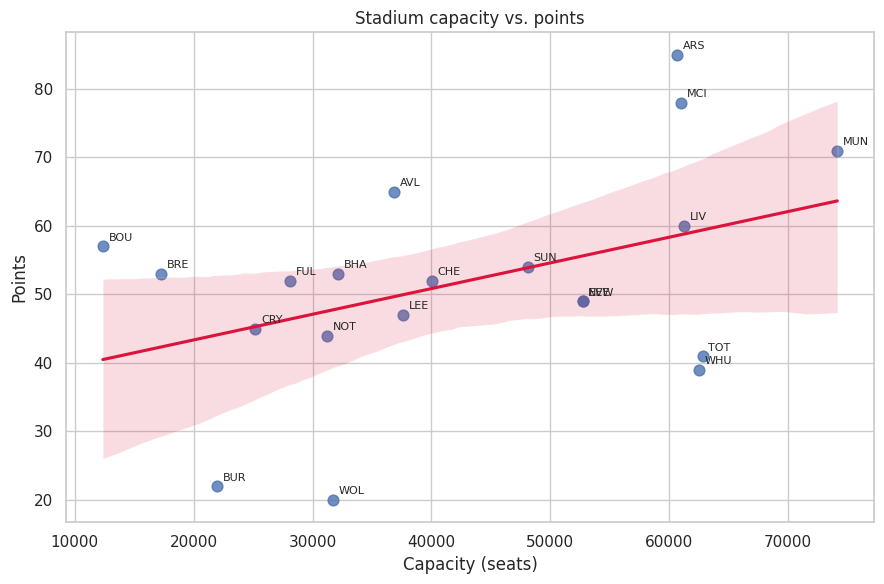

In [41]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.regplot(data=df, x="capacity", y="points", ax=ax, scatter_kws={"s": 60}, line_kws={"color": "crimson"})
for _, r in df.iterrows():
    ax.annotate(r["tla"], (r["capacity"], r["points"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_title("Stadium capacity vs. points"); ax.set_xlabel("Capacity (seats)"); ax.set_ylabel("Points")
plt.tight_layout(); fig.savefig("1_scatter.png", dpi=150); plt.show()

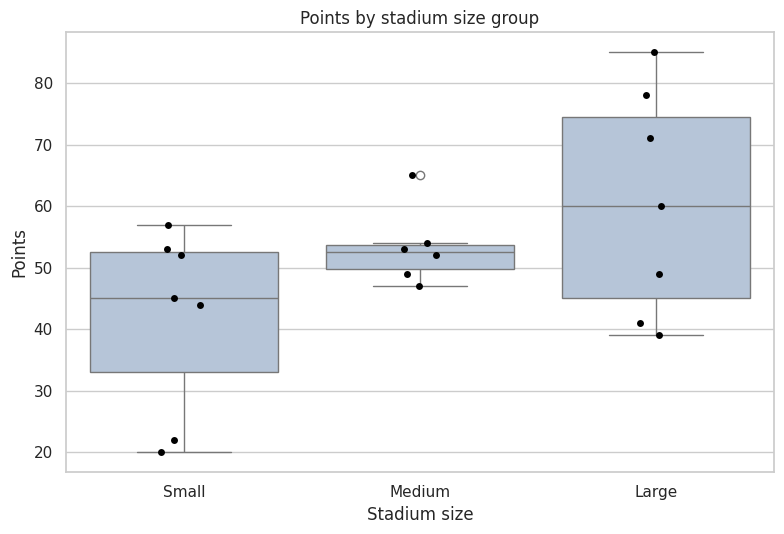

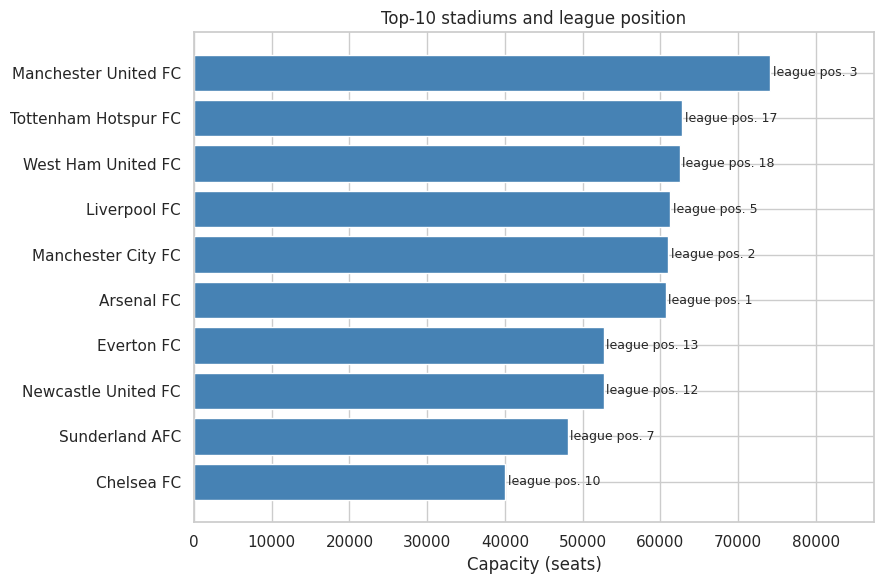

In [42]:
fig, ax = plt.subplots(figsize=(8, 5.5))
order = ["Small", "Medium", "Large"]
sns.boxplot(data=df, x="size_group", y="points", order=order, ax=ax, color="lightsteelblue")
sns.stripplot(data=df, x="size_group", y="points", order=order, ax=ax, color="black", size=5)
ax.set_title("Points by stadium size group"); ax.set_xlabel("Stadium size"); ax.set_ylabel("Points")
plt.tight_layout(); fig.savefig("2_boxplot.png", dpi=150); plt.show()

top10 = df.nlargest(10, "capacity").sort_values("capacity")
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top10["club_api"], top10["capacity"], color="steelblue")
for bar, pos in zip(bars, top10["position"]):
    ax.text(bar.get_width() + 300, bar.get_y() + bar.get_height() / 2, f"league pos. {pos}", va="center", fontsize=9)
ax.set_xlim(0, top10["capacity"].max() * 1.18)
ax.set_title("Top-10 stadiums and league position"); ax.set_xlabel("Capacity (seats)")
plt.tight_layout(); fig.savefig("3_bar.png", dpi=150); plt.show()

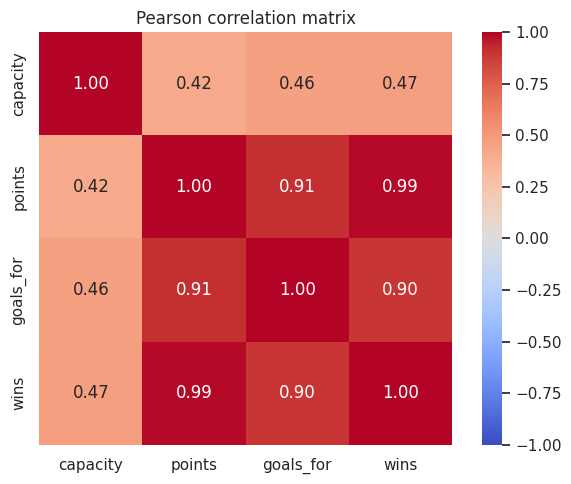

In [43]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df[["capacity", "points", "goals_for", "wins"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Pearson correlation matrix")
plt.tight_layout(); fig.savefig("4_heatmap.png", dpi=150); plt.show()